# Import

In [11]:
import time
import tqdm
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42) #Seme naključnega generatorja

# Parametri energije
K, Gama, lam = 1.0, 1.0, 1.0     # utež ploščine, obsega in dolžin stranic
R = 1.0 #Polmer kroga v katerega vrišeom polinom N-te stopnje

# Funkcije

In [12]:
def naredi_poligon(R = 1.0, n = 6, eps = 0.0, rng = rng):
    dfi = 2 * np.pi / n
    fi = dfi * np.arange(n) + rng.uniform(-eps, eps, n) * dfi
    r = R * (1 + rng.uniform(-eps, eps, n))
    return np.column_stack([r * np.cos(fi), r * np.sin(fi)])

def stranice(tocke_poligona):
    l = []
    for i,xy in enumerate(tocke_poligona):
        x0,y0 = xy
        x1,y1 = tocke_poligona[(i+1)%len(tocke_poligona)]
        dx = x1 - x0
        dy = y1 - y0
        d = np.sqrt(dx**2 + dy**2)
        l.append(d)
    return l

def obseg(tocke_poligona):
    return sum(stranice(tocke_poligona))


def ploscina(tocke_poligona):
    """Ploščina po formuli vezalk (shoelace)."""
    t = np.array(tocke_poligona)
    x, y = t[:, 0], t[:, 1]
    return 0.5 * abs(np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y))


def tezisce(tocke_poligona):
    """Masno središče oglišč."""
    xcm = 0.0
    ycm = 0.0
    norm = len(tocke_poligona)
    for i,xy in enumerate(tocke_poligona):
        x0,y0 = xy
        xcm += x0
        ycm += y0
    xcm = xcm/norm
    ycm = ycm/norm
    return [xcm, ycm]


def referencne(R = 1.0, n = 6):
    l0 =2*R*np.sin(np.pi/float(n))
    o0 = n*l0
    A0 = 0.5*n * R**2 * np.sin(2*np.pi /n)
    r = {"l0":l0,"o0":o0, "A0":A0}
    return r #set raje izvozimo kot dict

def energija(t, ref, K=K, Gama=Gama, lam=lam):
    """Mehanska energija celice; ref = (A0, P0, l0)."""
    A0, P0, l0 = ref
    # TODO
    pass

def narisi_celico(pos):
    plt.figure(figsize = (4,4),)
    for i,xy in enumerate(pos):
        x0,y0 = xy
        x1,y1 = pos[(i+1)%len(pos)]
        #print(i,x0,y0,x1,y1)
        plt.scatter(x0,y0, s = 50, zorder = 1, color='orange')
        plt.plot([x0,x1],[y0,y1], lw = 2, color = 'orange', zorder = 0)
    plt.axis('equal')
    plt.axis('off')
    plt.show()
    plt.close()

class Celica:
    def __init__(self, R = 1.0, n = 6, eps = 0.0, 
                 rng = rng,
                 Ka = K, Ko = Gama, Kl = lam, natancnost = 6):
        self.R = R
        self.n = n
        self.eps = eps
        self.rng = rng
        self.pos = naredi_poligon(R,n,eps,rng)
        self.ref = referencne(R,n)
        self.A0 = self.ref["A0"]
        self.P0 = self.ref["o0"]
        self.l0 = self.ref["l0"]
        self.Ka = Ka
        self.Ko = Ko
        self.Kl = Kl
        self.natancnost = natancnost
        
    def energija(self):
        E1 = np.round((self.A0 - ploscina(self.pos))**2, self.natancnost)
        E2 = np.round((self.P0 - obseg(self.pos))**2, self.natancnost)
        l = stranice(self.pos)
        E3 = np.round(sum((li - self.l0)**2 for li in l), self.natancnost)
        #print("E1 = ", E1)
        #print("E2 = ", E2)
        #print("E3 = ", E3)
        return self.Ka*E1 + self.Ko*E2 + self.Kl*E3
    
    def relaksacija(self):
        Eold = self.energija()
        stop = 0
        succes = 0
        while(stop<100*self.n):
            select = self.rng.integers(0,self.n)
            pos_old = self.pos[select].copy()
            self.pos[select] += self.rng.uniform(-0.01,0.01) ## !Pazi
            Enew = self.energija()
            if (Enew < Eold):
                succes += 1
                Eold = Enew
            else:
                self.pos[select] = pos_old
            stop += 1
        print(f"Success: {succes}/{stop}, Energy: {Eold}")

# Test

In [13]:
np.arange(6)*30

array([  0,  30,  60,  90, 120, 150])

In [14]:
epitel = Celica(natancnost = 6, eps = 0.1)
epitel.energija()

np.float64(0.075847)

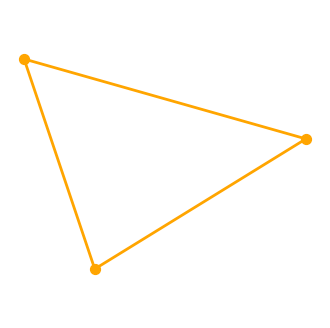

Success: 131/300, Energy: 0.034096


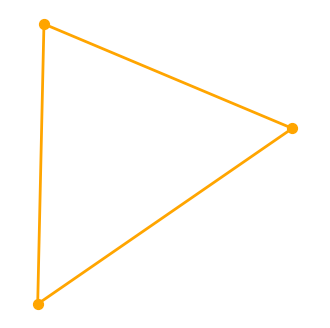

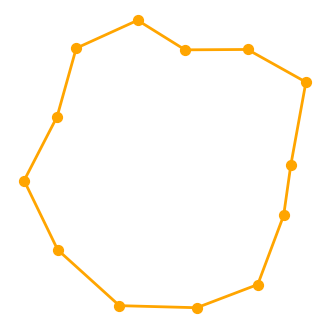

Success: 222/1300, Energy: 0.028824000000000002


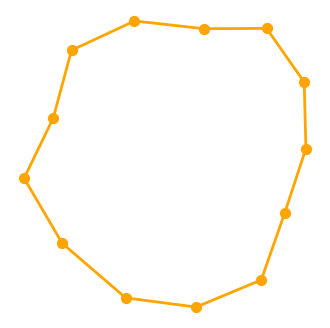

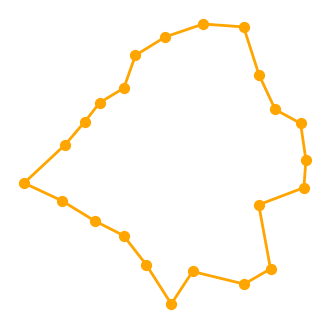

Success: 650/2300, Energy: 0.364557


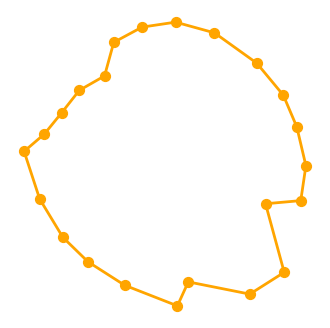

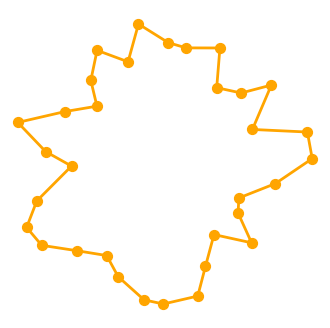

Success: 1192/3300, Energy: 1.533086


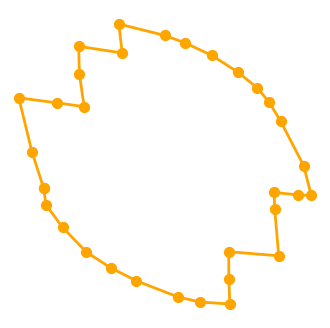

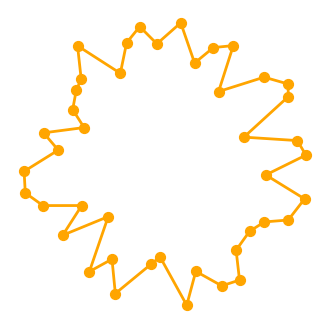

Success: 1465/4300, Energy: 4.176301


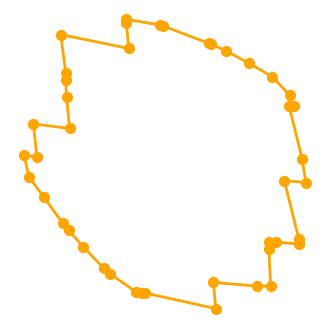

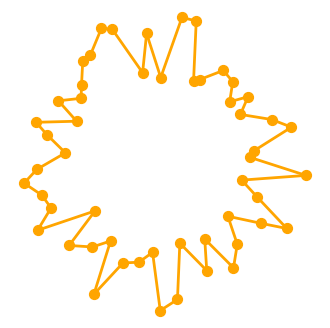

Success: 1588/5300, Energy: 14.625851


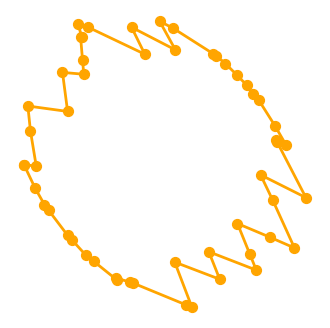

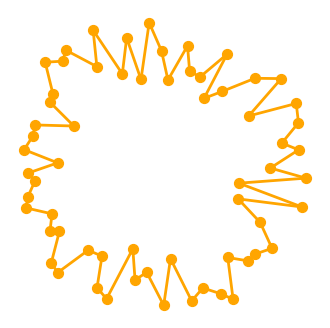

Success: 1769/6300, Energy: 23.280529


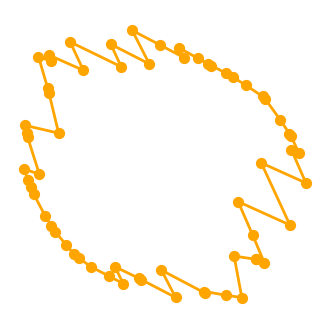

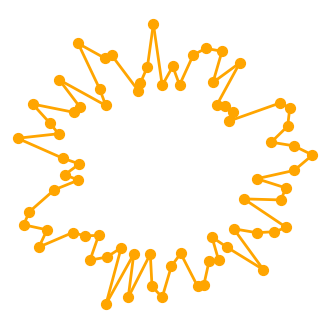

Success: 1903/7300, Energy: 31.52989


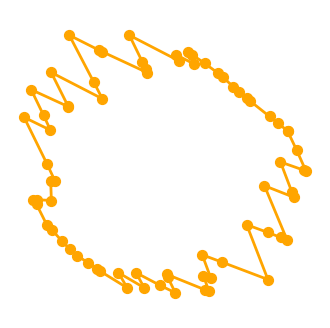

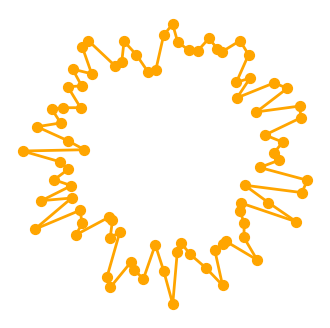

Success: 2012/8300, Energy: 34.078041999999996


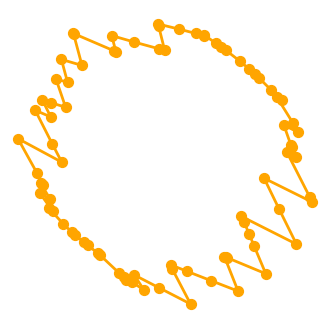

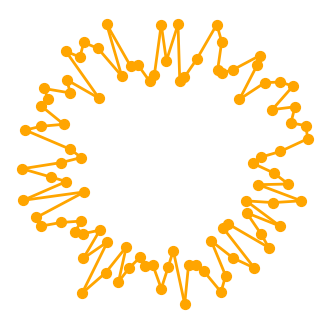

Success: 2357/9300, Energy: 67.549662


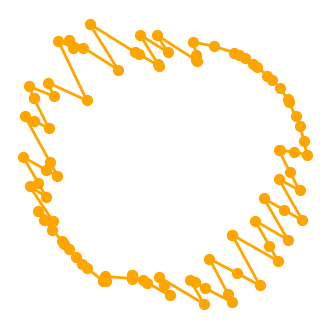

In [15]:
x = []
y = []
for order in range(3,101,10):
    cell = Celica(n = order, natancnost = 6, eps = 0.3)
    narisi_celico(cell.pos)
    cell.relaksacija()
    narisi_celico(cell.pos)


# Gradientni spust (gradient descent)

## Ozadje

Energija celice $E(x_1, y_1, \dots, x_n, y_n)$ je funkcija $2n$ koordinat oglišč. Lahko si jo predstavljamo kot **energijsko pokrajino** v $2n$-razsežnem prostoru: vsaka oblika celice je ena točka v tem prostoru, pravilni $n$-kotnik pa je dno doline ($E = 0$).

**Gradient** energije

$$
\nabla E = \left[\frac{\partial E}{\partial x_1}, \frac{\partial E}{\partial y_1}, \dots, \frac{\partial E}{\partial x_n}, \frac{\partial E}{\partial y_n}\right]
$$

kaže v smer, v kateri energija najhitreje narašča. Če oglišča premaknemo za majhen $\delta\mathbf r$, se energija spremeni za

$$
\Delta E \approx \nabla E \cdot \delta\mathbf r .
$$

Pri izbrani dolžini premika je $\Delta E$ najbolj negativna, ko je $\delta\mathbf r$ usmerjen nasprotno gradientu. Izberemo torej $\delta\mathbf r = -\eta\,\nabla E$. Takrat je $\Delta E \approx -\eta\,|\nabla E|^2 \le 0$, zato se energija pri dovolj majhnem $\eta$ v vsakem koraku zmanjša. Tako dobimo **gradientni spust**:

$$
\mathbf v_i^{(t+1)} = \mathbf v_i^{(t)} - \eta\,\nabla_{\mathbf v_i} E ,
$$

kjer je $\eta$ **hitrost učenja** (angl. *learning rate*), $\nabla_{\mathbf v_i} E = \left(\partial E/\partial x_i,\ \partial E/\partial y_i\right)$ pa del gradienta, ki pripada oglišču $\mathbf v_i$.

### Fizikalni pomen

Vektor $\mathbf F_i = -\nabla_{\mathbf v_i} E$ je **sila** na oglišče $i$. Celice živijo pri zelo majhnem Reynoldsovem številu: viskozno trenje prevlada nad vztrajnostjo, zato je hitrost oglišča sorazmerna sili, $\gamma\,\dot{\mathbf v}_i = \mathbf F_i$ (*prekomerno dušeno gibanje*). Če to enačbo rešimo z Eulerjevo metodo s časovnim korakom $\Delta t$, dobimo natanko gradientni spust z $\eta = \Delta t/\gamma$. Gradientni spust je zato tudi preprost model **dinamike** celice in ne le metoda za iskanje minimuma. Na enak način se oglišča premikajo v verteksnih modelih tkiv.

### Primerjava z metodo Monte Carlo

| | Monte Carlo (pohlepni) | Gradientni spust |
|---|---|---|
| premik | naključno oglišče, naključna smer | vsa oglišča hkrati, smer $-\nabla E$ |
| poteza | lahko je zavrnjena | se vedno izvede |
| potrebuje | samo $E$ | $E$ in $\nabla E$ |
| temperatura | da (Metropolis) | ne, postopek je determinističen |

Obe metodi najdeta le **lokalni** minimum. Gradient v smereh premika in zasuka cele celice (ničelne smeri) je enak nič, zato se masno središče in usmerjenost celice spremenita le toliko, kolikor to zahteva relaksacija nesimetrične začetne oblike.

### Numerični gradient

Analitičnega gradienta ne izpeljemo, temveč ga ocenimo s **končnimi diferencami** (slika spodaj). Vsako oglišče posebej premaknemo za majhen $\Delta$ v smeri $x$, izračunamo energijo $E_{n,x}$ in oglišče vrnemo na mesto. Enako ponovimo v smeri $y$ in dobimo $E_{n,y}$:

$$
\nabla_{\mathbf v_i} E \approx \left(\frac{E_{n,x} - E_{\rm old}}{\Delta},\ \frac{E_{n,y} - E_{\rm old}}{\Delta}\right).
$$

En korak zahteva $2n + 1$ izračunov energije. Napaka enostranske diference je reda $\Delta$, simetrične $\left[E(x+\Delta) - E(x-\Delta)\right]/2\Delta$ pa reda $\Delta^2$ (vendar zahteva $4n$ izračunov). Prevelik $\Delta$ pokvari oceno odvoda, premajhen pa poveča vpliv zaokrožitvenih napak.

> **Pozor:** `Celica.energija()` zaokroži posamezne člene na `natancnost` decimalk. Pri `natancnost = 6` in $\Delta = 10^{-6}$ je razlika $E_{n,x} - E_{\rm old}$ le nekaj enot zadnje decimalke in gradient je neuporaben. Za gradientni spust zato uporabimo `natancnost = 15`.

![Gradientni spust: numerični gradient s končnimi diferencami in posodobitev oglišč](SLIKE/Gradient_descent.png)

### Izbira hitrosti učenja $\eta$

Blizu minimuma je energija približno kvadratna, $E \approx \tfrac12\,\delta\mathbf r^{\,T} H\,\delta\mathbf r$, kjer je $H$ Hessejeva matrika. V lastni smeri z lastno vrednostjo $k$ se odmik v enem koraku pomnoži s $(1 - \eta k)$:

- postopek je **stabilen**, če je $|1 - \eta k| < 1$ za vse $k$, torej $\eta < 2/k_{\max}$. Pri večjem $\eta$ oglišča prenihajo minimum in energija eksponentno naraste. Za šestkotnik je $k_{\max} \approx 23$, zato mora biti $\eta < 0{,}087$,
- smeri z $k > 0$ se relaksirajo eksponentno, odmik pada kot $(1 - \eta k)^t$. Najpočasnejša med njimi je smer z najmanjšim neničelnim $k$ (za šestkotnik $k \approx 3$).

**Mehke smeri.** Hessejeva matrika pravilnega $n$-kotnika ima kar $n$ ničelnih lastnih vrednosti. Tri ustrezajo premiku in zasuku cele celice. Preostalih $n-3$ pa so spremembe oblike, pri katerih vse stranice ohranijo dolžino $l_0$. Med poligoni z enako dolgimi stranicami ima pravilni največjo ploščino (izoperimetrična neenakost), zato se ploščina v teh smereh spremeni šele v drugem redu, $A - A_0 \propto \delta^2$, energija pa je **kvartična**, $E \propto \delta^4$. Gradient je tam sorazmeren $\delta^3$ in hitro postane majhen. Iz $\dot\delta \propto -\delta^3$ sledi $\delta \propto t^{-1/2}$ in $E \propto t^{-2}$: energija ne pada eksponentno, temveč **potenčno**. To je počasen rep krivulje $E(t)$, ki se v log–log merilu asimptotsko približuje premici z naklonom $-2$. Enako upočasnitev opazimo tudi pri metodi Monte Carlo.

Podobno kot pri metodi Monte Carlo lahko $\eta$ sproti **prilagajamo**: če se energija po koraku poveča, korak zavrnemo in $\eta$ razpolovimo, sicer $\eta$ nekoliko povečamo. Tako se izognemo nestabilnosti: $\eta$ se sam ustali okoli meje stabilnosti $2/k_{\max}$, kar je največji še uporaben korak.

## Funkcije za gradientni spust

In [16]:
def gradient_energije(celica, delta=1e-6):
    """Numerični gradient energije (enostranska diferenca, glej sliko).
    Vrne array (n, 2): vrstica i je (dE/dx_i, dE/dy_i)."""
    E_old = celica.energija()
    grad = np.zeros_like(celica.pos)
    for i in range(celica.n):
        for k in range(2):                       # k = 0: smer x, k = 1: smer y
            staro = celica.pos[i, k]
            celica.pos[i, k] = staro + delta     # premaknemo eno koordinato enega oglišča
            grad[i, k] = (celica.energija() - E_old) / delta   # (E_n - E_old) / Delta
            celica.pos[i, k] = staro             # oglišče vrnemo na staro mesto
    return grad


def gradientni_spust(celica, eta=0.05, delta=1e-6, n_iter=2000, tol=1e-10, prilagodi=False):
    """Relaksacija celice z gradientnim spustom: v_i <- v_i - eta * grad_i E.
    prilagodi=True: če energija naraste, korak zavrnemo in eta razpolovimo, sicer eta *= 1.2.
    Vrne (zgodovina energije, zgodovina eta)."""
    E = celica.energija()
    zgod_E, zgod_eta = [E], [eta]
    for it in range(n_iter):
        grad = gradient_energije(celica, delta)
        stara = celica.pos.copy()
        celica.pos = stara - eta * grad          # vsa oglišča premaknemo hkrati
        E_nova = celica.energija()
        if prilagodi:
            if E_nova < E:
                E = E_nova
                eta *= 1.2
            else:
                celica.pos = stara               # zavrnemo korak
                eta *= 0.5
        else:
            E = E_nova
        zgod_E.append(E)
        zgod_eta.append(eta)
        if E < tol or not np.isfinite(E) or E > 1e6:   # konvergenca ali divergenca
            break
    return np.array(zgod_E), np.array(zgod_eta)

## Primer: relaksacija šestkotnika

E: 3.4583 -> 2.05e-06 v 2000 korakih (19.9 s)
težišče: [-0.1218  0.0924] -> [-0.122   0.0923]


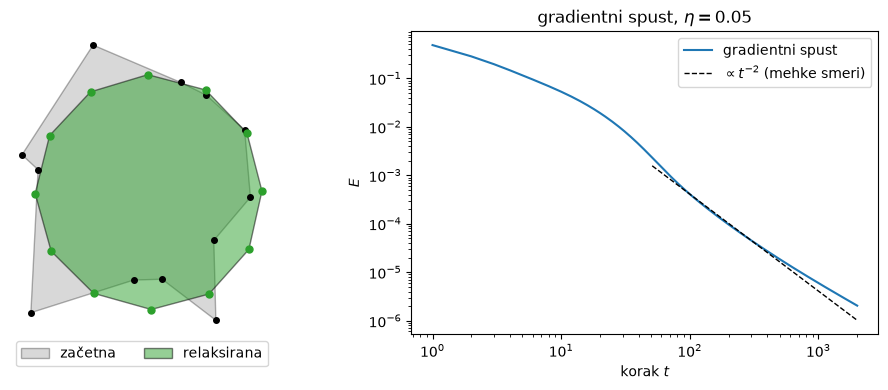

In [17]:
# Relaksacija popačenega šestkotnika z gradientnim spustom
celica_gs = Celica(n=12, eps=0.5, natancnost=15, rng=np.random.default_rng(7))
zacetna = celica_gs.pos.copy()

t_start = time.time()
E_gs, _ = gradientni_spust(celica_gs, eta=0.05, n_iter=2000)
print(f"E: {E_gs[0]:.4f} -> {E_gs[-1]:.2e} v {len(E_gs) - 1} korakih ({time.time() - t_start:.1f} s)")
print("težišče:", np.round(tezisce(zacetna), 4), "->", np.round(tezisce(celica_gs.pos), 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.fill(*zacetna.T, color="gray", alpha=0.3, ec="k", label="začetna")
ax1.fill(*celica_gs.pos.T, color="tab:green", alpha=0.5, ec="k", label="relaksirana")
ax1.plot(*zacetna.T, "ko", ms=4)
ax1.plot(*celica_gs.pos.T, "o", color="tab:green", ms=5)
ax1.set_aspect("equal")
ax1.axis("off")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
t_os = np.arange(1, len(E_gs))
ax2.loglog(t_os, E_gs[1:], label="gradientni spust")
ax2.loglog(t_os[50:], E_gs[100] * (t_os[50:] / 100) ** -2, "k--", lw=1, label=r"$\propto t^{-2}$ (mehke smeri)")
ax2.set_xlabel("korak $t$")
ax2.set_ylabel("$E$")
ax2.set_title(r"gradientni spust, $\eta = 0.05$")
ax2.legend()
fig.tight_layout()
plt.show()

## Izbira hitrosti učenja $\eta$

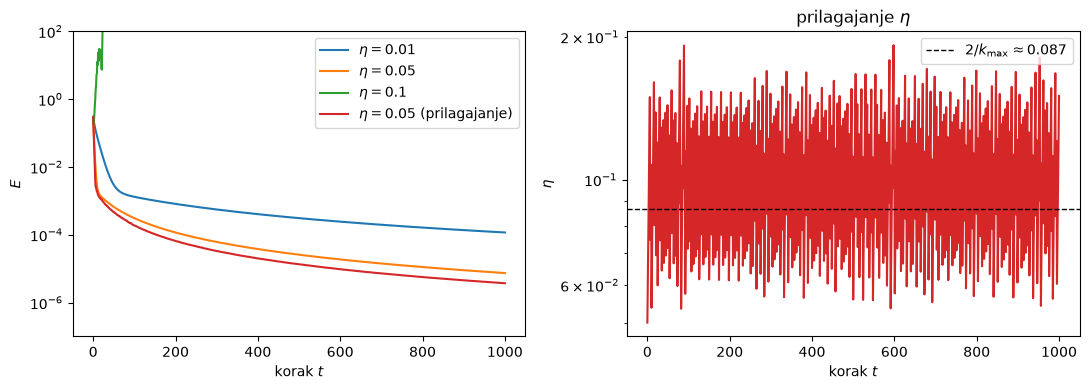

In [18]:
# Vpliv hitrosti učenja eta (in prilagajanje eta)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for eta, prilagodi in [(0.01, False), (0.05, False), (0.1, False), (0.05, True)]:
    c = Celica(n=6, eps=0.3, natancnost=15, rng=np.random.default_rng(7))
    E_h, eta_h = gradientni_spust(c, eta=eta, n_iter=1000, prilagodi=prilagodi)
    oznaka = rf"$\eta = {eta}$" + (" (prilagajanje)" if prilagodi else "")
    ax1.semilogy(E_h, label=oznaka)
    if prilagodi:
        ax2.semilogy(eta_h, color="tab:red")
ax1.set_ylim(1e-7, 1e2)
ax1.set_xlabel("korak $t$")
ax1.set_ylabel("$E$")
ax1.legend()
ax2.set_xlabel("korak $t$")
ax2.axhline(2 / 23, color="k", ls="--", lw=1, label=r"$2/k_{\max} \approx 0.087$")
ax2.set_ylabel(r"$\eta$")
ax2.set_title(r"prilagajanje $\eta$")
ax2.legend()
fig.tight_layout()
plt.show()

## Vzporedna primerjava: Monte Carlo in gradientni spust

Isto popačeno celico relaksiramo z obema metodama. Metodi pošteno primerjamo po **številu izračunov energije**, saj je to najdražji del obeh algoritmov:

- **Monte Carlo** (pohlepni): ena poskusna poteza stane **1** izračun energije. Naključno oglišče premaknemo za $(\delta x, \delta y)$, kjer sta $\delta x$ in $\delta y$ neodvisna in enakomerno porazdeljena na $[-a, a]$. Potezo sprejmemo le, če se energija zmanjša. Korak $a$ prilagajamo tako, da je delež sprejetih potez v intervalu $[0{,}2;\ 0{,}3]$.
- **Gradientni spust**: en korak stane $2n + 1$ izračunov energije ($2n$ za gradient in enega za novo energijo), vendar premakne vsa oglišča hkrati v najboljši smeri.

Obema metodama damo enako število izračunov energije. Gradientni spust tako naredi $2n+1$-krat manj korakov kot Monte Carlo poskusov.

In [19]:
def relaksacija_mc(celica, n_iter=20_000, korak=0.05, prilagodi=True, p_cilj=(0.2, 0.3), rng=None, zgod_pos=None):
    """Pohlepna relaksacija Monte Carlo: naključno oglišče premaknemo za (dx, dy) iz [-korak, korak]^2,
    potezo sprejmemo le, če se energija zmanjša. Korak prilagajamo glede na delež sprejetih potez p.
    zgod_pos: če podamo seznam, vanj po vsakem poskusu shranimo kopijo oglišč.
    Vrne (zgodovina energije, zgodovina koraka)."""
    rng = celica.rng if rng is None else rng
    E = celica.energija()
    p = 0.5                                       # drseče povprečje deleža sprejetih potez
    zgod_E, zgod_k = [E], [korak]
    if zgod_pos is not None:
        zgod_pos.append(celica.pos.copy())
    for it in range(n_iter):
        i = rng.integers(celica.n)                # naključno oglišče
        staro = celica.pos[i].copy()
        celica.pos[i] += rng.uniform(-korak, korak, 2)   # neodvisen premik v x in y
        E_nova = celica.energija()
        sprejeto = E_nova < E
        if sprejeto:
            E = E_nova
        else:
            celica.pos[i] = staro                 # zavrnemo potezo
        if prilagodi:
            p = 0.99 * p + 0.01 * sprejeto
            if p < p_cilj[0]:
                korak *= 0.99
            elif p > p_cilj[1]:
                korak *= 1.01
        zgod_E.append(E)
        zgod_k.append(korak)
        if zgod_pos is not None:
            zgod_pos.append(celica.pos.copy())
    return np.array(zgod_E), np.array(zgod_k)


def gradientni_spust_pos(celica, n_iter, zgod_pos, **kwargs):
    """Gradientni spust, ki po vsakem koraku shrani oglišča v seznam zgod_pos."""
    zgod_pos.append(celica.pos.copy())
    E_h, eta_h = [celica.energija()], []
    for it in range(n_iter):
        E_k, eta_k = gradientni_spust(celica, n_iter=1, **kwargs)   # en korak
        kwargs["eta"] = eta_k[-1]                 # prilagojeni eta prenesemo v naslednji korak
        E_h.append(E_k[-1])
        zgod_pos.append(celica.pos.copy())
    return np.array(E_h)

In [25]:
n_osn = 36
eps_osn = 0.5                                     # popačenje začetne celice
N_eval = 26_000                                   # skupno število izračunov energije za vsako metodo
cena_gs = 2 * n_osn + 1                           # izračunov energije na korak gradientnega spusta

# enaka začetna celica za obe metodi
celica_mc = Celica(n=n_osn, eps=eps_osn, natancnost=15, rng=np.random.default_rng(7))
celica_gs2 = Celica(n=n_osn, eps=eps_osn, natancnost=15, rng=np.random.default_rng(7))
zacetna_cmp = celica_mc.pos.copy()

t_start = time.time()
pos_mc = []
E_mc, k_mc = relaksacija_mc(celica_mc, n_iter=N_eval, korak=0.05, rng=np.random.default_rng(1), zgod_pos=pos_mc)
cas_mc = time.time() - t_start

t_start = time.time()
pos_gs = []
E_gs2 = gradientni_spust_pos(celica_gs2, n_iter=N_eval // cena_gs, zgod_pos=pos_gs, eta=0.05, prilagodi=True, tol=0)
cas_gs = time.time() - t_start

eval_mc = np.arange(len(E_mc))                    # izračuni energije po vsakem poskusu MC
eval_gs = cena_gs * np.arange(len(E_gs2))         # izračuni energije po vsakem koraku GS

def prvi_pod(E, ev, meja):
    """Število izračunov energije, ko E prvič pade pod mejo."""
    k = np.argmax(E < meja)
    return ev[k] if E[k] < meja else None

print(f"{'metoda':18s} {'E_konec':>10s} {'N_eval(E<1e-3)':>15s} {'N_eval(E<1e-5)':>15s} {'čas [s]':>8s}")
for ime, E, ev, cas in [("Monte Carlo", E_mc, eval_mc, cas_mc), ("gradientni spust", E_gs2, eval_gs, cas_gs)]:
    print(f"{ime:18s} {E[-1]:10.2e} {str(prvi_pod(E, ev, 1e-3)):>15s} {str(prvi_pod(E, ev, 1e-5)):>15s} {cas:8.1f}")

metoda                E_konec  N_eval(E<1e-3)  N_eval(E<1e-5)  čas [s]
Monte Carlo          1.49e-05            3698            None     11.9
gradientni spust     4.30e-05            2993            None      8.8


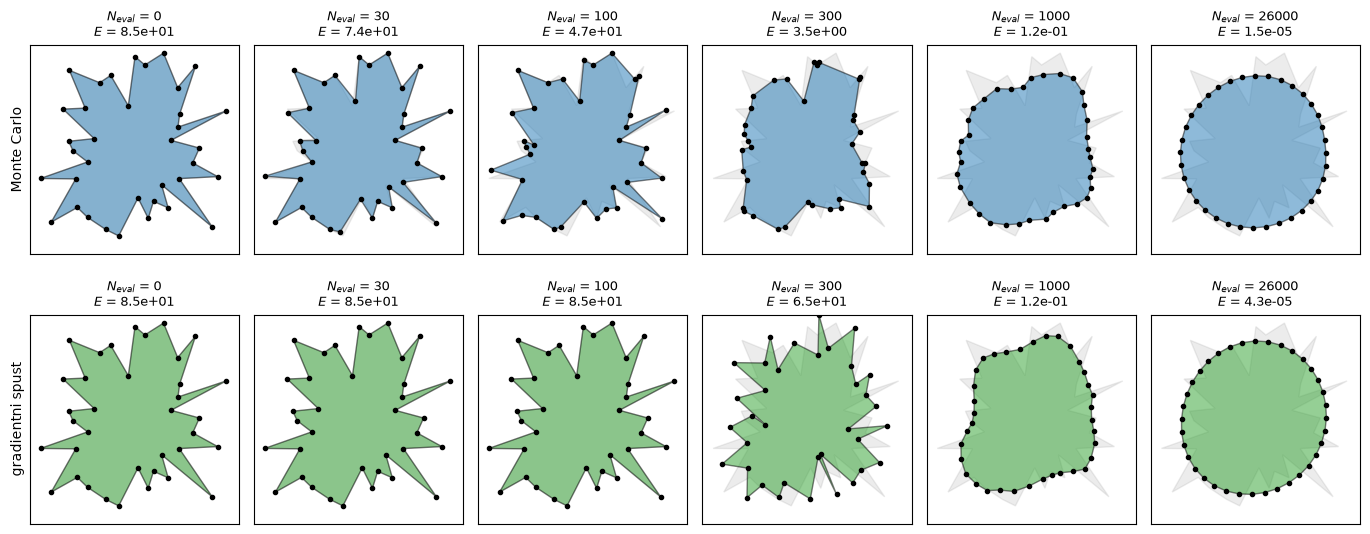

In [26]:
# Posnetki obeh relaksacij pri enakem številu izračunov energije
posnetki = [0, 30, 100, 300, 1000, N_eval]
fig, osi = plt.subplots(2, len(posnetki), figsize=(2.3 * len(posnetki), 5.8))
for j, ev in enumerate(posnetki):
    for vrstica, (ime, pos_h, E_h, korak_ev, barva) in enumerate([
            ("Monte Carlo", pos_mc, E_mc, 1, "tab:blue"),
            ("gradientni spust", pos_gs, E_gs2, cena_gs, "tab:green")]):
        k = min(ev // korak_ev, len(pos_h) - 1)   # indeks posnetka pri ev izračunih energije
        ax = osi[vrstica, j]
        ax.fill(*zacetna_cmp.T, color="gray", alpha=0.15)
        ax.fill(*pos_h[k].T, color=barva, alpha=0.5, ec="k")
        ax.plot(*pos_h[k].T, "ko", ms=3)
        ax.set_title(f"$N_{{eval}}$ = {ev}\n$E$ = {E_h[k]:.1e}", fontsize=9)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlim(-1.4, 1.4)
        ax.set_ylim(-1.4, 1.4)
        if j == 0:
            ax.set_ylabel(ime)
fig.tight_layout()
plt.show()

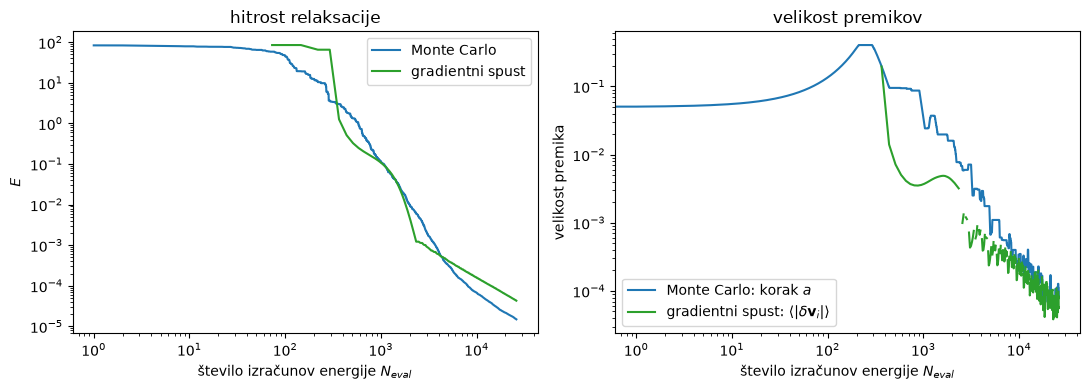

In [27]:
# Energija v odvisnosti od števila izračunov energije in velikost koraka
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.loglog(eval_mc[1:], E_mc[1:], color="tab:blue", label="Monte Carlo")
ax1.loglog(eval_gs[1:], E_gs2[1:], color="tab:green", label="gradientni spust")
ax1.set_xlabel("število izračunov energije $N_{eval}$")
ax1.set_ylabel("$E$")
ax1.legend()
ax1.set_title("hitrost relaksacije")

# premik oglišča na izračun energije: MC korak a, GS pa povprečni premik oglišča / (2n+1)
premik_gs = np.array([np.linalg.norm(b - a, axis=1).mean() for a, b in zip(pos_gs[:-1], pos_gs[1:])])
premik_gs[premik_gs == 0] = np.nan                # zavrnjeni koraki (prilagajanje eta) se ne narišejo
ax2.loglog(eval_mc, k_mc, color="tab:blue", label="Monte Carlo: korak $a$")
ax2.loglog(eval_gs[1:], premik_gs, color="tab:green", label=r"gradientni spust: $\langle|\delta\mathbf{v}_i|\rangle$")
ax2.set_xlabel("število izračunov energije $N_{eval}$")
ax2.set_ylabel("velikost premika")
ax2.legend()
ax2.set_title("velikost premikov")
fig.tight_layout()
plt.show()

**Opažanja.**

- **Daleč od minimuma je hitrejši gradientni spust.** V vsakem koraku premakne vsa oglišča v smeri največjega padca energije. Pri metodi Monte Carlo je veliko potez zavrnjenih, naključna smer pa le redko kaže v smer $-\nabla E$.
- **Blizu minimuma je na izračun energije nekoliko učinkovitejši Monte Carlo.** Krivulji se sekata pri $E \approx 10^{-3}$. Razlog je pogojenost: pri gradientnem spustu toge smeri omejujejo $\eta < 2/k_{\max}$, zato se celica v mehkih smereh premika zelo počasi, en korak pa stane $2n+1$ izračunov. Monte Carlo premika posamezna oglišča in korak $a$ prilagaja deležu sprejetih potez, zato ga toge smeri ne omejujejo na enak način.
- **Obe metodi se blizu minimuma upočasnita** zaradi kvartičnih mehkih smeri (potenčni rep $E(N_{eval})$).
- **Z analitičnim gradientom** bi bil en korak gradientnega spusta približno tako drag kot en izračun energije. Zelena krivulja bi se pomaknila za faktor $2n+1 = 13$ v levo in gradientni spust bi bil povsod hitrejši. Numerični gradient je zato glavna slabost naše izvedbe.
- **Monte Carlo** ne potrebuje gradienta in ga z Metropolisovim kriterijem razširimo na $T > 0$. **Gradientni spust** je determinističen in hkrati opisuje dušeno dinamiko celice.

**Za razmislek**

1. Pri katerem $\eta$ postane gradientni spust nestabilen? Oceni $k_{\max} \approx 2/\eta_{\rm meja}$.
2. Zakaj se energija na začetku hitro (eksponentno) zmanjša, nato pa le še potenčno ($E \propto t^{-2}$)? Kako pomaga prilagajanje $\eta$?
3. Primerjaj z metodo Monte Carlo: koliko izračunov energije potrebuje vsaka metoda, da doseže $E < 10^{-6}$? (En korak gradientnega spusta stane $2n+1$ izračunov.)
4. Ponovi za $n = 12$ in $n = 30$. Kaj se zgodi pri stalnem $\eta = 0{,}05$ in kaj s prilagajanjem?